# Lab 2: Set cover with hill climbing
Generates the 100 set-cover instances S1...S100 and solves them with two hill-climbing variants: reject and penalty.


In [1]:
from itertools import accumulate
from random import random,sample,seed,Random,choice
from math import sqrt
from collections import namedtuple
from matplotlib import pyplot as plt

## Instance generation
Instance Sₙ has n objects and n sets; set fᵢ covers i+1 random objects and costs 10·U + √(i·U). Each instance has its own `Random(n)`, so it's reproducible.

In [2]:
Instance = namedtuple('Instance', ['objects', 'family', 'costs'])

In [3]:
def single_instance(n: int) -> Instance:
    rng = Random(n)
    family = tuple(frozenset(rng.sample(range(n), k=s+1)) for s in range(n))
    objects = frozenset(a for a in range(n))
    ## Costs changed at some point during the introduction of the lab
    costs = tuple(10*rng.random()+ (s*rng.random())**2 for s in range(n))
   

    single = Instance(objects,family,costs)

    return single

In [4]:
single_instance(5)

Instance(objects=frozenset({0, 1, 2, 3, 4}), family=(frozenset({4}), frozenset({2, 4}), frozenset({0, 1, 4}), frozenset({0, 1, 2, 3}), frozenset({0, 1, 2, 3, 4})), costs=(5.739411879281008, 2.2454083975496495, 11.508795587176131, 7.31503205711077, 7.487636024468395))

In [5]:

def universe_generation(n: int) -> dict[int, Instance]:
    universe = {i: single_instance(i) for i in range(1,n+1)}
    return universe
    

In [6]:
universe_generation(3)

{1: Instance(objects=frozenset({0}), family=(frozenset({0}),), costs=(5.692038748222123,)),
 2: Instance(objects=frozenset({0, 1}), family=(frozenset({0}), frozenset({0, 1})), costs=(3.610574739836072, 8.818653604231026)),
 3: Instance(objects=frozenset({0, 1, 2}), family=(frozenset({0}), frozenset({0, 2}), frozenset({0, 1, 2})), costs=(6.055995301393269, 4.995687097788988, 3.9746462808592113))}

## Evaluating a solution
A solution is a frozenset of chosen set indices. `evaluate` returns its total cost and the number of uncovered objects.

In [7]:
def evaluate(instance: Instance, solution: frozenset[int]) -> tuple[float,int]:
    total_cost = sum(instance.costs[i] for i in solution)
    covered = frozenset().union(*(instance.family[i] for i in solution))
    uncovered= len(instance.objects - covered)
    return total_cost, uncovered 

In [8]:
test = single_instance(5)
print(evaluate(test, frozenset({4})))
print(evaluate(test, frozenset()))
print(evaluate(test, frozenset(range(5))))

(7.487636024468395, 0)
(0, 5)
(34.296283945585955, 0)


## Tweak
Makes one random move (add, remove or swap a set), choosing only among moves that are possible.

In [9]:
def tweak(instance: Instance, solution: frozenset[int], rng: Random) -> frozenset[int]:
    
    all_indices = frozenset(range(len(instance.family)))
    inside = solution
    outside = all_indices - inside

    possible_moves = []
    if inside:
        possible_moves.append('remove')
    if outside:
        possible_moves.append('add')
    if inside and outside:
        possible_moves.append('swap')

    # rng instead of the shared choice(), so runs are reproducible
    move = rng.choice(possible_moves)
    # sorted() always has the same order, so a given seed
    # always picks the same index
    if move == 'remove':
        removed = rng.choice(sorted(inside))
        new_solution = inside - {removed}           
    elif move == 'add':
        added = rng.choice(sorted(outside))
        new_solution = inside | {added}
    else:  
        removed = rng.choice(sorted(inside))
        added = rng.choice(sorted(outside))
        new_solution = (inside - {removed}) | {added}
    return new_solution



## Scoring
Reject: invalid solutions score infinity. Penalty: cost + weight × uncovered objects. Lower is better.

In [10]:
def reject_scoring(evaluation: tuple[float,int]) -> float:
    cost, uncovered = evaluation
    if uncovered > 0:
        return float('inf')
    else:
        return cost
    

In [11]:
single = single_instance(5)
sol1= frozenset({4})
sol2= frozenset({1,4})
sol3= frozenset({1})
sol4= frozenset()
for sol in [sol1, sol2, sol3, sol4]:
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, reject scoring: {reject_scoring(evaluate(single, sol))}")

solution: frozenset({4}), evaluation: (7.487636024468395, 0), reject scoring: 7.487636024468395
solution: frozenset({1, 4}), evaluation: (9.733044422018043, 0), reject scoring: 9.733044422018043
solution: frozenset({1}), evaluation: (2.2454083975496495, 3), reject scoring: inf
solution: frozenset(), evaluation: (0, 5), reject scoring: inf


In [12]:
# Nice that you add penalty scores
def penalty_scoring(evaluation: tuple[float,int], weight: float) -> float:
    cost, uncovered = evaluation
    # Add this to avoid double-checking in the penalty loop
    # if uncovered > 0:
    #     return float('inf')
    # else:
    return cost + weight * uncovered
    

In [13]:
single = single_instance(5)
sol1= frozenset({4})
sol2= frozenset({1,4})
sol3= frozenset({1})
sol4= frozenset()
for sol in [sol1, sol2, sol3, sol4]:
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, penalty scoring lambda1: {penalty_scoring(evaluate(single, sol), weight=1)}")
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, penalty scoring lambda0.5: {penalty_scoring(evaluate(single, sol), weight=0.5)}")

solution: frozenset({4}), evaluation: (7.487636024468395, 0), penalty scoring lambda1: 7.487636024468395
solution: frozenset({4}), evaluation: (7.487636024468395, 0), penalty scoring lambda0.5: 7.487636024468395
solution: frozenset({1, 4}), evaluation: (9.733044422018043, 0), penalty scoring lambda1: 9.733044422018043
solution: frozenset({1, 4}), evaluation: (9.733044422018043, 0), penalty scoring lambda0.5: 9.733044422018043
solution: frozenset({1}), evaluation: (2.2454083975496495, 3), penalty scoring lambda1: 5.2454083975496495
solution: frozenset({1}), evaluation: (2.2454083975496495, 3), penalty scoring lambda0.5: 3.7454083975496495
solution: frozenset(), evaluation: (0, 5), penalty scoring lambda1: 5
solution: frozenset(), evaluation: (0, 5), penalty scoring lambda0.5: 2.5


## Hill climbing: reject
Starts from all sets and accepts equal or better tweaks. stops after 1000 tweaks in a row without improvement.

In [14]:
def hill_climb_reject(instance: Instance, rng: Random, patience: int = 1000, max_steps: int = 100_000) -> tuple[frozenset[int], float, list[float]]:
    current = frozenset(range(len(instance.family)))
    current_score = reject_scoring(evaluate(instance, current))
    history = [current_score]
    # Also very nice to add the patience value
    no_improvement_steps = 0
    for step in range(max_steps):
        candidate = tweak(instance, current, rng)
        candidate_score = reject_scoring(evaluate(instance, candidate))
        # Include all scores in history not just the "best ones"
        history.append(candidate_score)
        if candidate_score < current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps = 0
        elif candidate_score == current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps += 1
        else:
            no_improvement_steps += 1

        if no_improvement_steps >= patience:
            print(f"NO IMPROVEMENT IN STEP {step}") ## Added as verbose
            break
    return current, current_score, history

In [15]:
inst = single_instance(5)
best, best_score, hist = hill_climb_reject(inst, Random(0))
print(f"Best solution: {best}, Best score: {best_score}")


NO IMPROVEMENT IN STEP 1007
Best solution: frozenset({1, 3}), Best score: 9.56044045466042


Instance: Instance(objects=frozenset({0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38}), family=(frozenset({13}), frozenset({16, 24}), frozenset({1, 12, 14}), frozenset({0, 25, 36, 16}), frozenset({1, 4, 11, 18, 22}), frozenset({0, 35, 6, 22, 23, 27}), frozenset({32, 4, 6, 17, 19, 25, 29}), frozenset({0, 2, 36, 12, 16, 20, 27, 30}), frozenset({2, 38, 8, 18, 20, 22, 24, 27, 30}), frozenset({1, 5, 6, 11, 13, 15, 18, 19, 25, 30}), frozenset({0, 1, 6, 7, 8, 14, 16, 20, 24, 26, 28}), frozenset({34, 5, 6, 8, 14, 15, 17, 21, 23, 27, 30, 31}), frozenset({32, 1, 3, 5, 6, 9, 10, 11, 12, 18, 20, 23, 31}), frozenset({32, 33, 3, 4, 35, 6, 7, 8, 38, 11, 14, 21, 26, 29}), frozenset({0, 33, 34, 35, 4, 5, 3, 6, 9, 11, 17, 18, 20, 25, 29}), frozenset({37, 6, 8, 9, 10, 11, 13, 14, 18, 21, 22, 24, 27, 28, 30, 31}), frozenset({0, 1, 34, 3, 4, 6, 8, 11, 15, 16, 21, 24, 25, 26, 27, 29, 30}), frozenset({1, 2, 3, 3

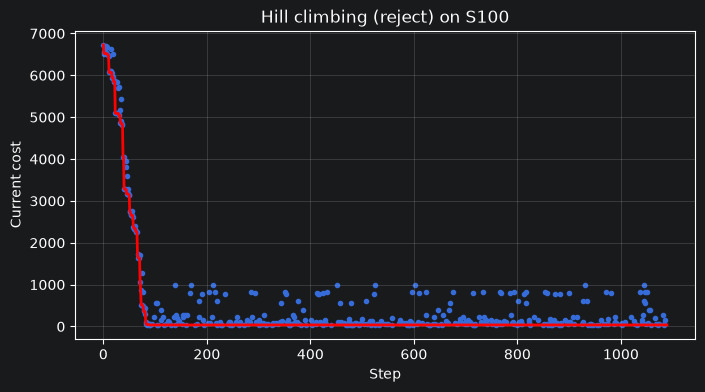

Best solution: frozenset({38}), Best score: 36.68873315553212


In [16]:
inst = single_instance(39)
print(f"Instance: {inst}")
best, best_score, hist = hill_climb_reject(inst, Random(0))

# Better plotting to see the whole history
plt.figure(figsize=(8, 4))                    # new, empty figure: 8 wide, 4 tall (in inches)
plt.plot(range(len(hist)), list(accumulate(hist, min)), color='red', linewidth=2)                   # draw the history as a line
_ = plt.scatter(range(len(hist)), hist, marker='.')
plt.xlabel("Step")                            # label the x axis
plt.ylabel("Current cost")                    # label the y axis
plt.title("Hill climbing (reject) on S100")    # title above the plot
plt.grid(alpha=0.3)                           # faint grid lines (alpha = transparency)
plt.show()                                    # display it
print(f"Best solution: {best}, Best score: {best_score}")


NO IMPROVEMENT IN STEP 999
NO IMPROVEMENT IN STEP 1004
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1007
NO IMPROVEMENT IN STEP 1023
NO IMPROVEMENT IN STEP 1045
NO IMPROVEMENT IN STEP 1037
NO IMPROVEMENT IN STEP 1022
NO IMPROVEMENT IN STEP 1024
NO IMPROVEMENT IN STEP 1069
NO IMPROVEMENT IN STEP 1319
NO IMPROVEMENT IN STEP 1042
NO IMPROVEMENT IN STEP 1079
NO IMPROVEMENT IN STEP 1053
NO IMPROVEMENT IN STEP 1092
NO IMPROVEMENT IN STEP 1043
NO IMPROVEMENT IN STEP 1192
NO IMPROVEMENT IN STEP 1052
NO IMPROVEMENT IN STEP 1243
NO IMPROVEMENT IN STEP 1283
NO IMPROVEMENT IN STEP 1058
NO IMPROVEMENT IN STEP 1069
NO IMPROVEMENT IN STEP 1090
NO IMPROVEMENT IN STEP 1069
NO IMPROVEMENT IN STEP 1157
NO IMPROVEMENT IN STEP 1086
NO IMPROVEMENT IN STEP 1103
NO IMPROVEMENT IN STEP 1433
NO IMPROVEMENT IN STEP 1159
NO IMPROVEMENT IN STEP 1079
NO IMPROVEMENT IN STEP 1369
NO IMPROVEMENT IN STEP 1209
NO IMPROVEMENT IN STEP 1249
NO IMPROVEMENT IN STEP 1687
NO IMPROVEMENT IN STE

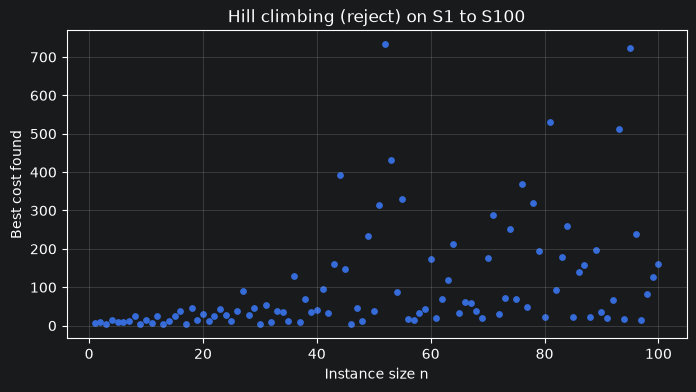

In [17]:
ns = []       # x values: instance size
costs = []    # y values: best cost found

for n in range(1, 101):
    _, score, _ = hill_climb_reject(single_instance(n), Random(0))
    ns.append(n)
    costs.append(score)

plt.figure(figsize=(8, 4))
plt.scatter(ns, costs, s=15)                  # one dot per instance (s = dot size)
plt.xlabel("Instance size n")
plt.ylabel("Best cost found")
plt.title("Hill climbing (reject) on S1 to S100")
plt.grid(alpha=0.3)
plt.show()


## Hill climbing: penalty
Same loop but with penalty scoring. Can pass through invalid solutions, so it returns the best valid solution seen.

In [18]:
def hill_climb_penalty(instance: Instance, rng: Random, weight: float,
                       patience: int = 1000, max_steps: int = 100_000) -> tuple[frozenset[int], float, list[float]]:
    current = frozenset(range(len(instance.family)))
    current_eval = evaluate(instance, current)                 
    current_cost, current_uncovered = current_eval
    current_score = penalty_scoring(current_eval, weight)
    history = [current_score]
    no_improvement_steps = 0

    best_valid = current
    best_valid_cost = current_cost

    for step in range(max_steps):
        candidate = tweak(instance, current, rng)
        candidate_eval = evaluate(instance, candidate)          
        candidate_score = penalty_scoring(candidate_eval, weight)
        history.append(candidate_score)
        if candidate_score < current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps = 0
        elif candidate_score == current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps += 1
        else:
            no_improvement_steps += 1

        #  best valid solution
        cand_cost, cand_uncovered = candidate_eval
        if cand_uncovered == 0 and cand_cost<best_valid_cost:                                         # valid AND cheaper than best_valid_cost
            best_valid, best_valid_cost = candidate, cand_cost


        if no_improvement_steps >= patience:
            print(f"NO IMPROVEMENT IN STEP {step}") ## Added as verbose
            break

    return best_valid, best_valid_cost, history


In [19]:
inst = single_instance(59)
for w in [1,5, 25]:
    sol, cost, hist = hill_climb_penalty(inst, Random(0), weight=w)
    print(f"weight={w}: best valid {sorted(sol)}, cost {cost:.2f}, steps {len(hist)}")


NO IMPROVEMENT IN STEP 1183
weight=1: best valid [28, 53], cost 42.64, steps 1185
NO IMPROVEMENT IN STEP 1293
weight=5: best valid [5, 46, 53], cost 36.79, steps 1295
NO IMPROVEMENT IN STEP 1449
weight=25: best valid [5, 46, 53], cost 36.79, steps 1451


In [20]:
inst = single_instance(5)
for w in [25, 0.5]:
    sol, cost, hist = hill_climb_penalty(inst, Random(0), weight=w)
    print(f"weight={w}: best valid {sorted(sol)}, cost {cost:.2f}, steps {len(hist)}")


NO IMPROVEMENT IN STEP 1007
weight=25: best valid [1, 3], cost 9.56, steps 1009
NO IMPROVEMENT IN STEP 1015
weight=0.5: best valid [4], cost 7.49, steps 1017


## Comparison on S1...S100
Runs reject and penalty (weights 1, 5, 25) on all instances, then summarises them against reject and plots them.

In [21]:
ns = list(range(1, 101))
results = {"reject": [], "weight=1": [], "weight=5": [], "weight=25": []}

for n in ns:
    inst = single_instance(n)
    _, score, _ = hill_climb_reject(inst, Random(0))
    results["reject"].append(score)
    for w in [1, 5, 25]:
        _, score, _ = hill_climb_penalty(inst, Random(0), weight=w)
        results[f"weight={w}"].append(score)

NO IMPROVEMENT IN STEP 999
NO IMPROVEMENT IN STEP 1000
NO IMPROVEMENT IN STEP 1000
NO IMPROVEMENT IN STEP 999
NO IMPROVEMENT IN STEP 1004
NO IMPROVEMENT IN STEP 1001
NO IMPROVEMENT IN STEP 1000
NO IMPROVEMENT IN STEP 1004
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1009
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1006
NO IMPROVEMENT IN STEP 1007
NO IMPROVEMENT IN STEP 1015
NO IMPROVEMENT IN STEP 1007
NO IMPROVEMENT IN STEP 1007
NO IMPROVEMENT IN STEP 1023
NO IMPROVEMENT IN STEP 1023
NO IMPROVEMENT IN STEP 1021
NO IMPROVEMENT IN STEP 1023
NO IMPROVEMENT IN STEP 1045
NO IMPROVEMENT IN STEP 1028
NO IMPROVEMENT IN STEP 1035
NO IMPROVEMENT IN STEP 1045
NO IMPROVEMENT IN STEP 1037
NO IMPROVEMENT IN STEP 1041
NO IMPROVEMENT IN STEP 1037
NO IMPROVEMENT IN STEP 1036
NO IMPROVEMENT IN STEP 1022
NO IMPROVEMENT IN STEP 1050
NO IMPROVEMENT IN STEP 1022
NO IMPROVEMENT IN STEP

In [22]:
reject = results["reject"]

print(f"{'method':>10} | {'average':>7} | better | worse | ties")
for label, costs in results.items():
    average = sum(costs) / len(costs)
    wins = sum(c < r for c, r in zip(costs, reject))      # strictly cheaper than reject
    losses = sum(c > r for c, r in zip(costs, reject))    # strictly more expensive
    ties = len(costs) - wins - losses                     # everything else is equal
    print(f"{label:>10} | {average:7.2f} | {wins:6} | {losses:5} | {ties:4}")


    method | average | better | worse | ties
    reject |  104.92 |      0 |     0 |  100
  weight=1 |   82.14 |     34 |    24 |   42
  weight=5 |   36.98 |     50 |     7 |   43
 weight=25 |   39.86 |     41 |     5 |   54


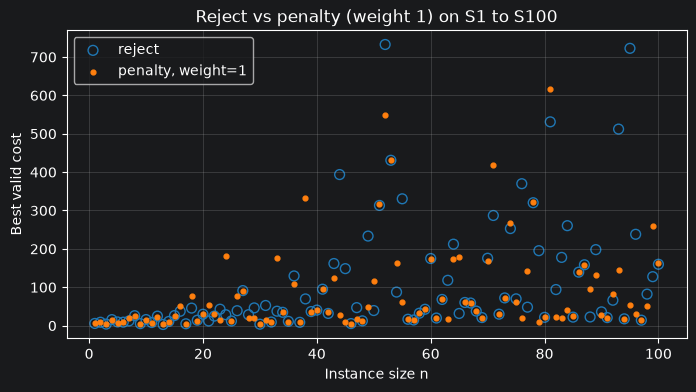

In [23]:
plt.figure(figsize=(8, 4))
plt.scatter(ns, results["reject"], s=50, facecolors="none", edgecolors="tab:blue", label="reject")
plt.scatter(ns, results["weight=1"], s=12, color="tab:orange", label="penalty, weight=1")
plt.xlabel("Instance size n")
plt.ylabel("Best valid cost")
plt.title("Reject vs penalty (weight 1) on S1 to S100")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


NO IMPROVEMENT IN STEP 1183


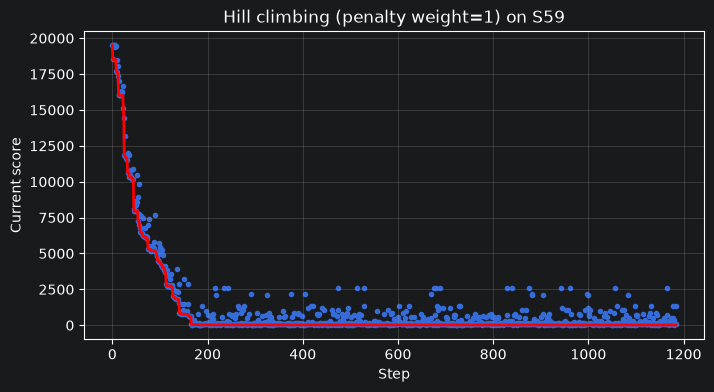

Best solution: frozenset({28, 53}), Best score: 42.63896597458827


In [24]:
inst = single_instance(59)

best, best_score, hist = hill_climb_penalty(inst, Random(0), weight=1)

plt.figure(figsize=(8, 4))                    # new, empty figure: 8 wide, 4 tall (in inches)
plt.plot(range(len(hist)), list(accumulate(hist, min)), color='red', linewidth=2)                   # draw the history as a line
_ = plt.scatter(range(len(hist)), hist, marker='.')
plt.xlabel("Step")                            # label the x axis
plt.ylabel("Current score")                    # label the y axis
plt.title("Hill climbing (penalty weight=1) on S59")    # title above the plot
plt.grid(alpha=0.3)                           # faint grid lines (alpha = transparency)
plt.show()                                    # display it
print(f"Best solution: {best}, Best score: {best_score}")
